# From GemPy to finite-difference process simulation: octree-based property averaging

This notebook shows how to map a GemPy geological model onto a **rectilinear
finite-difference (FD) grid** — as used by geothermal process simulators such as
**SHEMAT-Suite** — while treating cells that are cut by a unit interface properly:
instead of assigning the property of whatever unit happens to sit at the cell
center, their properties are **averaged (upscaled)** from sub-cell information
provided by GemPy's adaptive **octree refinement**.

Contents:

1. Build and compute a geological model with octree refinement
2. Inspect the octree: adaptive refinement at unit interfaces
3. Upscale onto a rectilinear FD grid: volume fractions
4. Averaging laws: cell-center mapping vs. arithmetic / geometric / harmonic / power means
5. Full effective conductivity **tensor** from interface orientation
6. Mapping to main axes (principal values vs. grid-aligned diagonal)
7. Non-uniform rectilinear grids (SHEMAT-Suite style `delx`/`dely`/`delz`)


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Ellipse

import gempy as gp

try:
    from gempy.modules.grids.fd_property_averaging import (
        RectilinearGrid, upscale_octree_to_rectilinear)
except ImportError:
    # Installed gempy does not ship the module yet: load it from the repository
    import importlib.util
    _module_path = Path().resolve().parents[1] / 'gempy' / 'modules' / 'grids' / 'fd_property_averaging.py'
    _spec = importlib.util.spec_from_file_location('fd_property_averaging', _module_path)
    _mod = importlib.util.module_from_spec(_spec)
    _spec.loader.exec_module(_mod)
    RectilinearGrid = _mod.RectilinearGrid
    upscale_octree_to_rectilinear = _mod.upscale_octree_to_rectilinear

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Setting Backend To: AvailableBackends.numpyIntel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.



## 1. Geological model with octree refinement

A simple anticline with three units — a shale cap rock (`rock1`), a sandstone
aquifer (`rock2`) and the basement — serves as demonstration model. Passing
`refinement=6` to `create_geomodel` activates the octree grid: the interpolation
is evaluated on a coarse root grid and cells intersected by an interface are
recursively subdivided, six levels deep (equivalent to a $64^3$ dense grid at
the finest level, but only evaluated where it matters).

In [2]:
extent = [0, 1000, 0, 1000, 0, 600]
REFINEMENT = 6

geo_model = gp.create_geomodel(
    project_name='anticline_fd_upscaling',
    extent=extent,
    refinement=REFINEMENT,
    structural_frame=gp.data.StructuralFrame.initialize_default_structure(),
)

# Upper horizon of the anticline (fold axis along y, crest at x = 500)
x_pts = np.array([100., 300., 500., 700., 900.])
z_top = 380. + 130. * np.exp(-((x_pts - 500.) / 300.) ** 2)

gp.add_surface_points(
    geo_model=geo_model,
    x=np.tile(x_pts, 2), y=np.repeat([250., 750.], x_pts.size), z=np.tile(z_top, 2),
    elements_names='surface1'
)
gp.add_orientations(
    geo_model=geo_model,
    x=[500.], y=[500.], z=[510.],
    elements_names=['surface1'], pole_vector=[[0, 0, 1]]
)

# Lower horizon: parallel surface 160 m below
element2 = gp.data.StructuralElement(
    name='surface2',
    color=next(geo_model.structural_frame.color_generator),
    surface_points=gp.data.SurfacePointsTable.from_arrays(
        x=np.tile(x_pts, 2), y=np.repeat([250., 750.], x_pts.size), z=np.tile(z_top - 160., 2),
        names='surface2'
    ),
    orientations=gp.data.OrientationsTable.initialize_empty()
)
geo_model.structural_frame.structural_groups[0].append_element(element2)

geo_model.update_transform(gp.data.GlobalAnisotropy.NONE)
gp.compute_model(geo_model)

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Setting Backend To: AvailableBackends.numpy


/Users/flow/opt/anaconda3/envs/diff-geomodelling/lib/python3.13/site-packages/gempy_engine/modules/activator/_soft_segment.py:95: RuntimeWarning: overflow encountered in exp
  return 1.0 / (1.0 + bt.t.exp(x))


Solutions(6 Octree Levels, 2 DualContouringMeshes)

## 2. Inside the octree: adaptive refinement at interfaces

Each octree level stores the cell centers that were evaluated at that level and
which cells were subdivided further. The *leaf* cells of all levels together
partition the model volume: large cells where the lithology is uniform, and
cells down to the finest level along the unit interfaces. This is exactly the
sub-cell information we need for property averaging — at a fraction of the cost
of a dense fine grid.

For visualization (and for the upscaling itself) the octree can also be expanded
to a virtual dense grid at any level via
`get_regular_grid_value_for_level`.

In [3]:
from gempy_engine.core.data.output.blocks_value_type import ValueType
from gempy_engine.modules.octrees_topology.octrees_topology_interface import \
    get_regular_grid_value_for_level

solutions = geo_model.solutions
octrees = solutions.octrees_output

ids_fine = np.rint(np.asarray(
    get_regular_grid_value_for_level(octrees, value_type=ValueType.ids))).astype(int)
print(f'{len(octrees)} octree levels, finest level as dense grid: {ids_fine.shape}')


def octree_grid_of(level):
    """Root grid accessor compatible with gempy_engine <= 2025.2 and newer."""
    root = level.grid_centers if hasattr(level, 'grid_centers') else level.grid
    return root.octree_grid


# The engine stores the octree in transformed (normalized) coordinates when the
# model has an input transform; rescale linearly back to world coordinates.
engine_extent = np.asarray(octree_grid_of(octrees[0]).orthogonal_extent, dtype=float)
world_extent = np.asarray(geo_model.grid.extent, dtype=float)
world_scale = (world_extent[1::2] - world_extent[::2]) / (engine_extent[1::2] - engine_extent[::2])


def octree_leaves(octrees, level_index):
    """World-coordinate centers and sizes of the leaf cells (= not further refined) of one level."""
    grid = octree_grid_of(octrees[level_index])
    centers = np.asarray(grid.values)
    if level_index == len(octrees) - 1:
        leaf_mask = np.ones(centers.shape[0], dtype=bool)
    else:  # active_cells of level l+1 marks which cells of level l were refined
        refined = np.asarray(
            octree_grid_of(octrees[level_index + 1]).active_cells).astype(bool).ravel()
        leaf_mask = ~refined
    centers_world = world_extent[::2] + (centers[leaf_mask] - engine_extent[::2]) * world_scale
    sizes_world = np.asarray(octrees[level_index].dxdydz) * world_scale
    return centers_world, sizes_world


for level_index in range(len(octrees)):
    leaves, (dx, dy, dz) = octree_leaves(octrees, level_index)
    print(f'level {level_index}: {leaves.shape[0]:6d} leaf cells of size '
          f'{dx:6.1f} x {dy:6.1f} x {dz:6.2f} m')

6 octree levels, finest level as dense grid: (64, 64, 64)
level 0:      0 leaf cells of size  500.0 x  500.0 x 300.00 m
level 1:      0 leaf cells of size  250.0 x  250.0 x 150.00 m
level 2:    276 leaf cells of size  125.0 x  125.0 x  75.00 m
level 3:    388 leaf cells of size   62.5 x   62.5 x  37.50 m
level 4:   1651 leaf cells of size   31.2 x   31.2 x  18.75 m
level 5:  82792 leaf cells of size   15.6 x   15.6 x   9.38 m


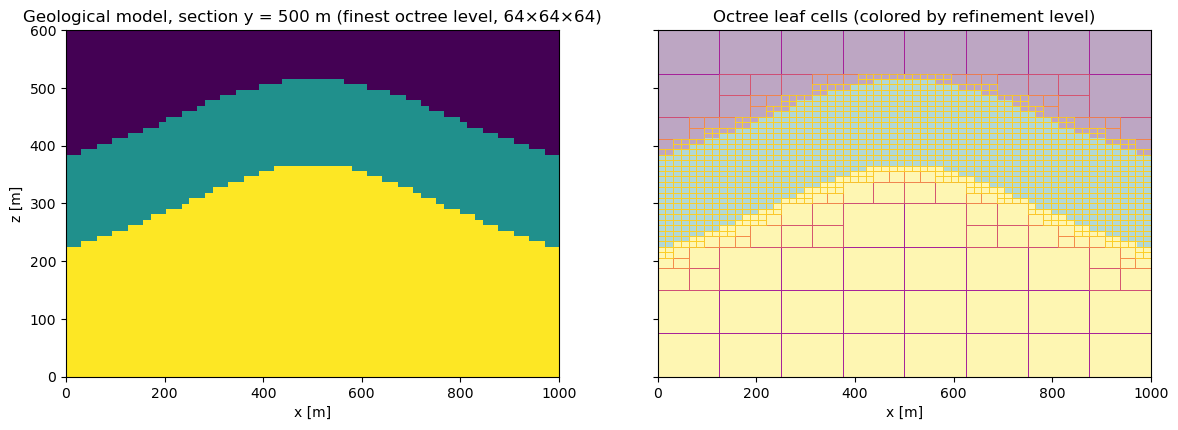

In [4]:
y_section = 500.
nfx, nfy, nfz = ids_fine.shape
j_fine = int((y_section - extent[2]) / (extent[3] - extent[2]) * nfy)
extent_xz = [extent[0], extent[1], extent[4], extent[5]]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
axes[0].imshow(ids_fine[:, j_fine, :].T, origin='lower', extent=extent_xz,
               cmap='viridis', aspect='auto')
axes[0].set_title(f'Geological model, section y = {y_section:.0f} m '
                  f'(finest octree level, {nfx}×{nfy}×{nfz})')
axes[0].set_xlabel('x [m]'); axes[0].set_ylabel('z [m]')

axes[1].imshow(ids_fine[:, j_fine, :].T, origin='lower', extent=extent_xz,
               cmap='viridis', aspect='auto', alpha=0.35)
level_colors = plt.cm.plasma(np.linspace(0, 0.9, len(octrees)))
for level_index in range(len(octrees)):
    leaves, (dx, dy, dz) = octree_leaves(octrees, level_index)
    # cells whose y-interval contains the section (half-open to be boundary-safe)
    in_section = leaves[(leaves[:, 1] - dy / 2 <= y_section) & (y_section < leaves[:, 1] + dy / 2)]
    for cx, cy, cz in in_section:
        axes[1].add_patch(mpatches.Rectangle((cx - dx / 2, cz - dz / 2), dx, dz,
                                             fill=False, ec=level_colors[level_index], lw=0.6))
axes[1].set_title('Octree leaf cells (colored by refinement level)')
axes[1].set_xlabel('x [m]')
plt.show()

## 3. Upscaling onto a rectilinear FD grid

We now define the simulation grid — here a uniform $20 \times 20 \times 12$
grid, i.e. cells of $50 \times 50 \times 50$ m, much coarser than the octree
resolution. The FD grid is fully independent of the octree layout; it only has
to lie within the model extent (and per-axis spacings may vary, see section 7).

`upscale_octree_to_rectilinear` expands the finest octree level and aggregates
its voxels into the FD cells, returning for every FD cell

* the **volume fractions** of each geological unit,
* the unit at the **cell center** (for the conventional direct mapping), and
* the **interface normal** (unit vector of the mean scalar-field gradient),
  used later for the tensor determination.

In [5]:
fd_grid = RectilinearGrid.from_resolution(extent, [20, 20, 12])
upscaled = upscale_octree_to_rectilinear(
    solutions, fd_grid,
    model_extent=geo_model.grid.extent  # world coordinates (the model uses an input transform)
)

n_cells = int(np.prod(upscaled.grid.resolution))
print(f'FD grid: {tuple(int(r) for r in upscaled.grid.resolution)} = {n_cells} cells')
print(f'unit ids: {upscaled.unit_ids}')
print(f'cells cut by an interface: {upscaled.mixed_cells.sum()} '
      f'({100 * upscaled.mixed_cells.sum() / n_cells:.1f} %)')

FD grid: (20, 20, 12) = 4800 cells
unit ids: [1 2 3]
cells cut by an interface: 860 (17.9 %)


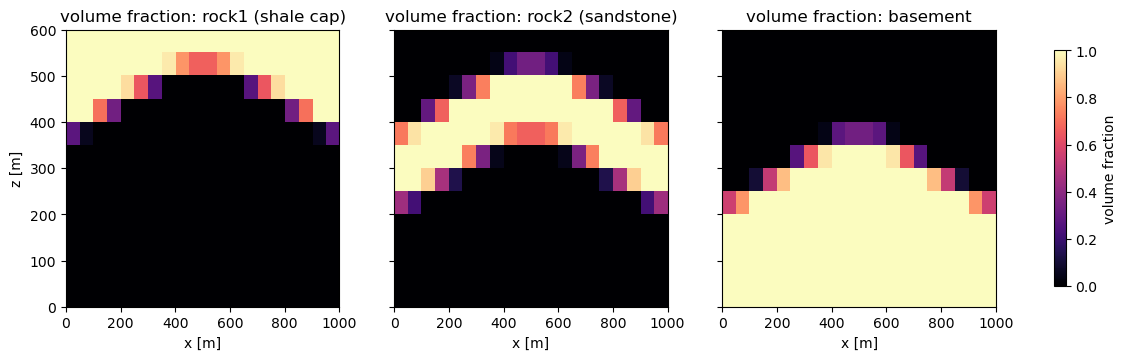

In [6]:
j = int((y_section - extent[2]) / (extent[3] - extent[2]) * upscaled.grid.resolution[1])

unit_names = {1: 'rock1 (shale cap)', 2: 'rock2 (sandstone)', 3: 'basement'}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for i, ax in enumerate(axes):
    im = ax.imshow(upscaled.fractions[:, j, :, i].T, origin='lower', extent=extent_xz,
                   cmap='magma', aspect='auto', vmin=0, vmax=1)
    ax.set_title(f'volume fraction: {unit_names[int(upscaled.unit_ids[i])]}')
    ax.set_xlabel('x [m]')
axes[0].set_ylabel('z [m]')
fig.colorbar(im, ax=axes, label='volume fraction', shrink=0.85)
plt.show()

## 4. Averaging laws

With volume fractions $\phi_i$ and unit conductivities $k_i$, the classical
volume-weighted averaging laws are

| law | formula | physical meaning |
|---|---|---|
| arithmetic | $k_a = \sum_i \phi_i k_i$ | exact for flow **parallel** to layering (upper / Voigt bound) |
| harmonic | $k_h = \left(\sum_i \phi_i / k_i\right)^{-1}$ | exact for flow **normal** to layering (lower / Reuss bound) |
| geometric | $k_g = \exp\left(\sum_i \phi_i \ln k_i\right)$ | common heuristic for disordered media |
| power ($p$) | $k_p = \left(\sum_i \phi_i k_i^p\right)^{1/p}$ | generalization: $p=1$ arithmetic, $p \to 0$ geometric, $p=-1$ harmonic |

Any effective scalar conductivity must satisfy $k_h \le k_\mathrm{eff} \le k_a$.
The conventional **cell-center mapping** is included as method `'center'` for
comparison — it does not average at all and simply picks the unit at the cell
center, producing the familiar staircase artifacts.

We assign thermal conductivities per unit id and map them with each law:

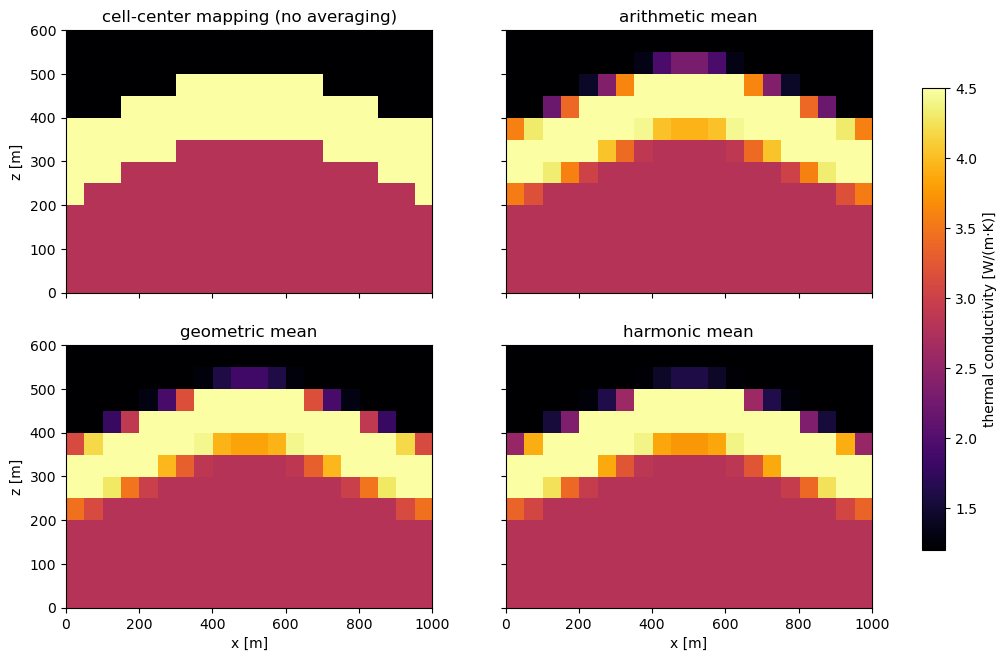

In [7]:
k_units = {
        1: 1.2,  # rock1: shale cap rock  [W/(m·K)]
        2: 4.5,  # rock2: quartz-rich sandstone
        3: 2.8,  # basement
}

k_center = upscaled.map_property(k_units, method='center')
k_arithmetic = upscaled.map_property(k_units, method='arithmetic')
k_geometric = upscaled.map_property(k_units, method='geometric')
k_harmonic = upscaled.map_property(k_units, method='harmonic')
k_power = upscaled.map_property(k_units, method='power', p=0.5)  # any exponent

# fundamental bounds hold everywhere
assert np.all(k_harmonic <= k_geometric + 1e-12) and np.all(k_geometric <= k_arithmetic + 1e-12)

fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), sharex=True, sharey=True)
for ax, data, title in zip(
        axes.ravel(),
        [k_center, k_arithmetic, k_geometric, k_harmonic],
        ['cell-center mapping (no averaging)', 'arithmetic mean',
         'geometric mean', 'harmonic mean']):
    im = ax.imshow(data[:, j, :].T, origin='lower', extent=extent_xz, cmap='inferno',
                   aspect='auto', vmin=min(k_units.values()), vmax=max(k_units.values()))
    ax.set_title(title)
for ax in axes[1]: ax.set_xlabel('x [m]')
for ax in axes[:, 0]: ax.set_ylabel('z [m]')
fig.colorbar(im, ax=axes, label='thermal conductivity [W/(m·K)]', shrink=0.8)
plt.show()

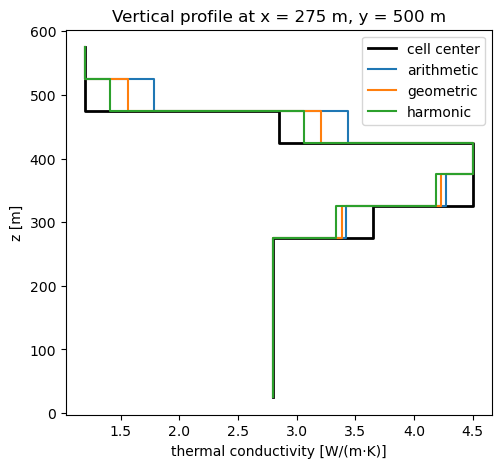

In [8]:
# Vertical profile through the western flank: the averaging laws smooth the
# staircase of the cell-center mapping in the interface cells
ix = 5
zc = upscaled.grid.z_centers
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.step(k_center[ix, j, :], zc, where='mid', color='k', lw=2, label='cell center')
for data, label in [(k_arithmetic, 'arithmetic'), (k_geometric, 'geometric'),
                    (k_harmonic, 'harmonic')]:
    ax.step(data[ix, j, :], zc, where='mid', label=label)
ax.set_xlabel('thermal conductivity [W/(m·K)]'); ax.set_ylabel('z [m]')
ax.set_title(f'Vertical profile at x = {upscaled.grid.x_centers[ix]:.0f} m, '
             f'y = {y_section:.0f} m')
ax.legend()
plt.show()

## 5. Full effective conductivity tensor

A cell cut by an interface is not isotropic: flow parallel to the interface sees
the arithmetic mean, flow normal to it the harmonic mean. With the interface
unit normal $\mathbf{n}$ (from the gradient of GemPy's implicit scalar field,
averaged over the cell), the classical laminate result gives the full effective
tensor

$$
\mathbf{K}_\mathrm{eff} \;=\; k_h \, \mathbf{n}\mathbf{n}^\top
\;+\; k_a \left(\mathbf{I} - \mathbf{n}\mathbf{n}^\top\right),
$$

which is exact for stationary flow through plane layers. Cells inside a single
unit remain isotropic, $\mathbf{K} = k\,\mathbf{I}$.

Below, the tensor is drawn as an ellipse (projected onto the section plane) for
every interface cell, together with the interface normal: along the fold flanks
the principal directions rotate with the dip of the layers, producing
**off-diagonal tensor entries** — cross-coupling that a scalar average cannot
represent.

tensor field shape: (20, 20, 12, 3, 3)


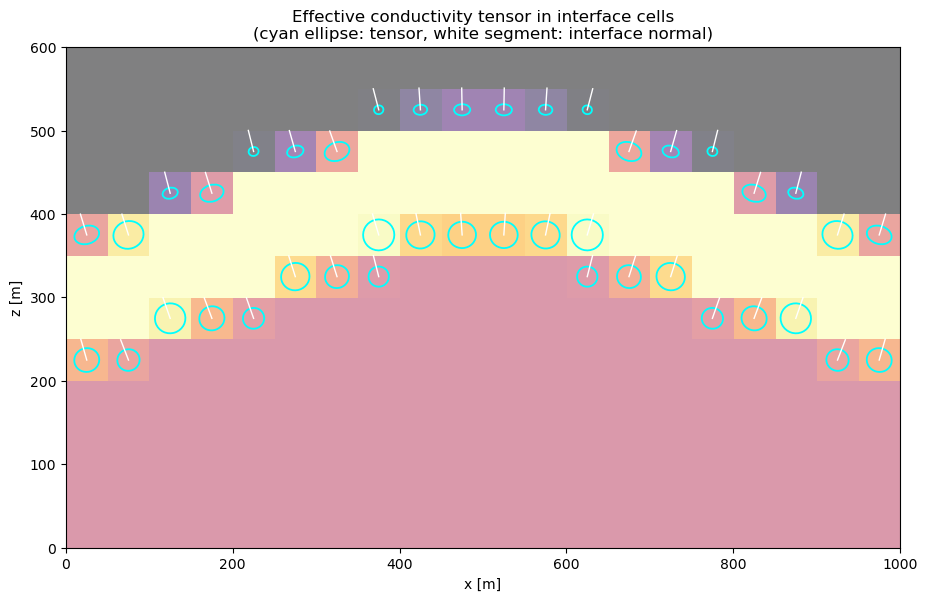

In [9]:
K_tensor = upscaled.full_tensor(k_units)   # shape (nx, ny, nz, 3, 3)
print('tensor field shape:', K_tensor.shape)

fig, ax = plt.subplots(figsize=(12, 6.5))
ax.imshow(k_geometric[:, j, :].T, origin='lower', extent=extent_xz, cmap='inferno',
          aspect='equal', alpha=0.5, vmin=min(k_units.values()), vmax=max(k_units.values()))
xc, zc = upscaled.grid.x_centers, upscaled.grid.z_centers
ellipse_scale = 38 / max(k_units.values())
for ix in range(upscaled.grid.resolution[0]):
    for iz in range(upscaled.grid.resolution[2]):
        if not upscaled.mixed_cells[ix, j, iz]:
            continue
        T_xz = K_tensor[ix, j, iz][np.ix_([0, 2], [0, 2])]  # project onto x-z plane
        w, v = np.linalg.eigh(T_xz)
        angle = np.degrees(np.arctan2(v[1, 1], v[0, 1]))
        ax.add_patch(Ellipse((xc[ix], zc[iz]), width=w[1] * ellipse_scale,
                             height=w[0] * ellipse_scale, angle=angle,
                             fill=False, ec='cyan', lw=1.3))
        n = upscaled.interface_normals[ix, j, iz]
        ax.plot([xc[ix], xc[ix] + n[0] * 26], [zc[iz], zc[iz] + n[2] * 26], color='w', lw=1)
ax.set_title('Effective conductivity tensor in interface cells\n'
             '(cyan ellipse: tensor, white segment: interface normal)')
ax.set_xlabel('x [m]'); ax.set_ylabel('z [m]')
plt.show()

## 6. Mapping to main axes

Many FD codes — SHEMAT-Suite among them — only accept **per-axis conductivities**
$k_x, k_y, k_z$, i.e. a diagonal tensor aligned with the grid. Two mappings are
provided:

* `principal_axes_tensor` — eigen-decomposition into principal values and
  principal directions. Lossless, but the principal directions generally do
  **not** coincide with the grid axes.
* `diagonal_tensor` — keep only $K_{xx}, K_{yy}, K_{zz}$ in grid coordinates.
  This is what effectively happens when the full tensor is fed into a simulator
  that ignores off-diagonal terms; the discarded cross-coupling $|K_{xz}|$ is a
  useful map of where this approximation matters (steeply dipping interfaces).

In [10]:
principal_values, principal_directions = upscaled.principal_axes_tensor(k_units)
k_diagonal = upscaled.diagonal_tensor(k_units)   # (nx, ny, nz, 3) -> kxx, kyy, kzz

# The interface cell with the strongest cross-coupling (on a fold flank) in detail:
candidates = np.argwhere(upscaled.mixed_cells[:, j, :])
ix, iz = candidates[np.argmax(np.abs(K_tensor[candidates[:, 0], j, candidates[:, 1], 0, 2]))]
cell = (int(ix), j, int(iz))
np.set_printoptions(precision=3, suppress=True)
print(f'interface cell {cell}:')
print('full tensor K =\n', K_tensor[cell])
print('principal values  :', principal_values[cell])
print('principal dir. (min):', principal_directions[cell][:, 0], ' <- interface normal')
print('interface normal   :', upscaled.interface_normals[cell])
print('grid-diagonal kx,ky,kz:', k_diagonal[cell])

interface cell (13, 10, 9):
full tensor K =
 [[ 3.506 -0.003 -0.322]
 [-0.003  3.62  -0.008]
 [-0.322 -0.008  2.711]]
principal values  : [2.596 3.62  3.62 ]
principal dir. (min): [0.334 0.009 0.942]  <- interface normal
interface normal   : [0.334 0.009 0.942]
grid-diagonal kx,ky,kz: [3.506 3.62  2.711]


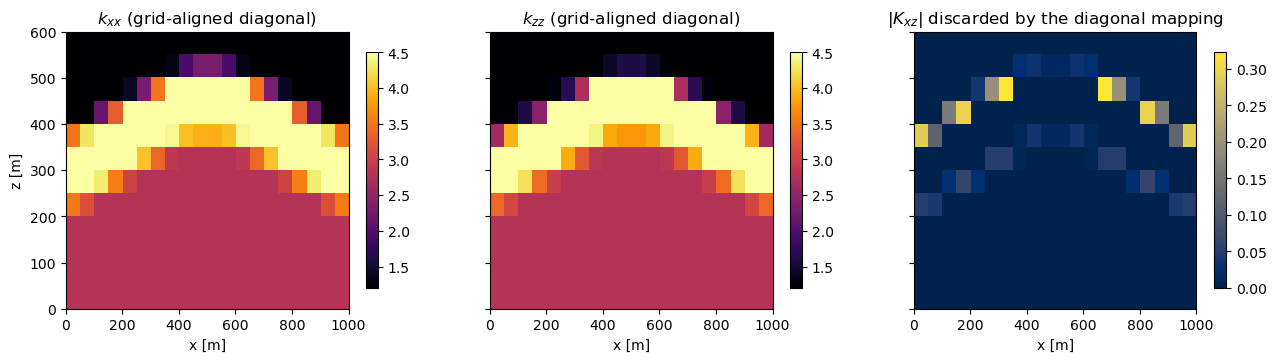

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 3.6), sharey=True)
im0 = axes[0].imshow(k_diagonal[:, j, :, 0].T, origin='lower', extent=extent_xz,
                     cmap='inferno', aspect='auto')
axes[0].set_title('$k_{xx}$ (grid-aligned diagonal)')
fig.colorbar(im0, ax=axes[0], shrink=0.85)
im1 = axes[1].imshow(k_diagonal[:, j, :, 2].T, origin='lower', extent=extent_xz,
                     cmap='inferno', aspect='auto')
axes[1].set_title('$k_{zz}$ (grid-aligned diagonal)')
fig.colorbar(im1, ax=axes[1], shrink=0.85)
im2 = axes[2].imshow(np.abs(K_tensor[:, j, :, 0, 2]).T, origin='lower', extent=extent_xz,
                     cmap='cividis', aspect='auto')
axes[2].set_title('$|K_{xz}|$ discarded by the diagonal mapping')
fig.colorbar(im2, ax=axes[2], shrink=0.85)
for ax in axes: ax.set_xlabel('x [m]')
axes[0].set_ylabel('z [m]')
plt.show()

## 7. Non-uniform rectilinear grids (SHEMAT-Suite style)

FD simulators typically allow variable spacing per axis (`delx`, `dely`,
`delz`) to refine the mesh around wells or thin aquifers.
`RectilinearGrid.from_spacing` accepts exactly such spacing arrays — the
upscaling itself is unchanged.

non-uniform grid resolution: (14, 10, 15)


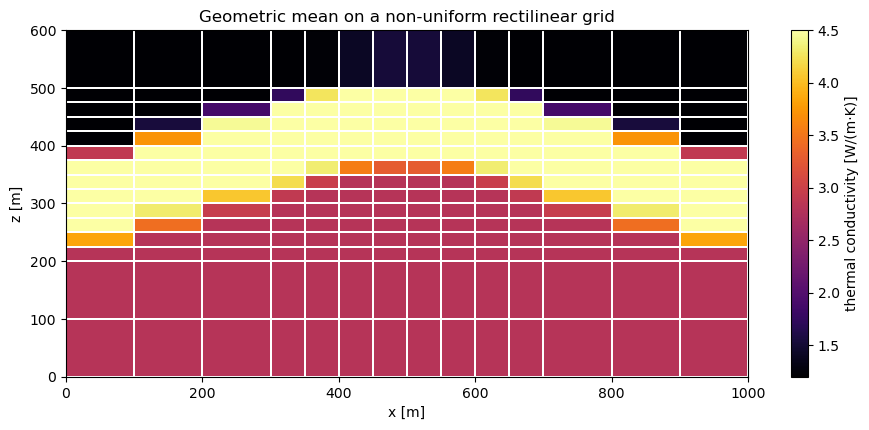

In [12]:
fd_grid_refined = RectilinearGrid.from_spacing(
    origin=[0., 0., 0.],
    dx=[100.] * 3 + [50.] * 8 + [100.] * 3,             # refined around the crest
    dy=[100.] * 10,
    dz=[100.] * 2 + [25.] * 12 + [100.],                # refined around the aquifer
)
upscaled_refined = upscale_octree_to_rectilinear(solutions, fd_grid_refined,
                                                 model_extent=geo_model.grid.extent)
k_refined = upscaled_refined.map_property(k_units, method='geometric')
print('non-uniform grid resolution:', tuple(int(r) for r in upscaled_refined.grid.resolution))

j2 = np.searchsorted(fd_grid_refined.y_edges, y_section) - 1
fig, ax = plt.subplots(figsize=(11, 4.5))
mesh = ax.pcolormesh(fd_grid_refined.x_edges, fd_grid_refined.z_edges,
                     k_refined[:, j2, :].T, cmap='inferno', edgecolors='w', lw=0.3,
                     vmin=min(k_units.values()), vmax=max(k_units.values()))
fig.colorbar(mesh, label='thermal conductivity [W/(m·K)]')
ax.set_title('Geometric mean on a non-uniform rectilinear grid')
ax.set_xlabel('x [m]'); ax.set_ylabel('z [m]')
plt.show()

## Summary

* GemPy's **octree refinement** provides sub-cell lithology information exactly
  where it is needed — at unit interfaces — and can be expanded level by level.
* `upscale_octree_to_rectilinear` aggregates the finest octree level into an
  arbitrary rectilinear FD grid: **volume fractions**, cell-center unit ids and
  **interface normals** per cell.
* `map_property` applies **different averaging laws** (center, arithmetic,
  geometric, harmonic, power mean) to any per-unit scalar property.
* `full_tensor` determines the **full effective conductivity tensor** per cell
  from the laminate rule (harmonic normal / arithmetic parallel to the
  interface); `principal_axes_tensor` and `diagonal_tensor` map it to **main
  axes** for simulators restricted to $k_x, k_y, k_z$.

The resulting arrays (`k_diagonal[..., 0/1/2]`, unit ids, fractions) are
C-ordered `(nx, ny, nz)` numpy arrays and can be written directly into a
SHEMAT-Suite input file (or any other FD code's property section).